# Worksheet 1 – Warehouse Robots and Optimization

### Students

* **Youssef Mohamed** — 202302010
* **Ziad Elnady** — 202301280
* **Kenzy Hazem** — 202300816

### Module Information

* **Module Leader:** Rasha Shoitan
* **Teaching Assistant:** Mohammed Adel


# Part A – Warehouse Robots in a Grid

**Assumptions**
- Grid is 6x6. Robots and packages are placed on different random cells.
- Each robot starts with 5 energy and moves randomly (up, down, left or right) to a cell that is inside the grid and not occupied by another robot.
- A move costs 1 energy. A package gives +3 energy and then disappears.
- If 2 or more robots choose the same cell in the same step, they all stay in place and each loses 1 extra energy (so -2 in total for that step).
- A robot with energy <= 0 is removed.
- Each contested cell counts as 1 collision.

In [1]:
import random
import matplotlib.pyplot as plt

SIZE = 6
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right

## Functions

In [2]:
def create_world(num_robots, num_packages):
    # make a list of all cells and shuffle it so the placement is random
    cells = [(r, c) for r in range(SIZE) for c in range(SIZE)]
    random.shuffle(cells)

    robots = []
    for i in range(num_robots):
        robots.append({"id": i + 1, "pos": cells.pop(), "energy": 5,
                       "alive": True, "packages": 0, "steps_alive": 0})

    packages = set()
    for i in range(num_packages):
        packages.add(cells.pop())

    return robots, packages


def show_grid(robots, packages):
    # R1, R2... = robots, P = package, . = empty cell
    for r in range(SIZE):
        line = ""
        for c in range(SIZE):
            text = " . "
            if (r, c) in packages:
                text = " P "
            for robot in robots:
                if robot["alive"] and robot["pos"] == (r, c):
                    text = "R" + str(robot["id"]) + " "
            line = line + text
        print(line)
    print()


def get_move(robot, robots):
    # cells that other robots are standing on
    occupied = []
    for other in robots:
        if other["alive"] and other["id"] != robot["id"]:
            occupied.append(other["pos"])

    options = []
    for dr, dc in MOVES:
        new_r = robot["pos"][0] + dr
        new_c = robot["pos"][1] + dc
        inside = 0 <= new_r < SIZE and 0 <= new_c < SIZE
        if inside and (new_r, new_c) not in occupied:
            options.append((new_r, new_c))

    if len(options) == 0:
        return None          # robot is boxed in, it waits
    return random.choice(options)


def one_step(robots, packages, show_steps=False):
    # returns the number of collisions in this step
    alive_robots = [r for r in robots if r["alive"]]

    # 1) every robot chooses where it wants to go
    targets = {}
    for robot in alive_robots:
        targets[robot["id"]] = get_move(robot, robots)

    # 2) count how many robots want each cell
    count = {}
    for t in targets.values():
        if t is not None:
            count[t] = count.get(t, 0) + 1

    # 3) move the robots
    for robot in alive_robots:
        target = targets[robot["id"]]
        robot["steps_alive"] += 1
        if target is None:
            if show_steps:
                print("  R" + str(robot["id"]), "is boxed in and waits")
            continue
        if count[target] > 1:
            robot["energy"] -= 2             # collision: stays, loses 1 + 1
            if show_steps:
                print("  R" + str(robot["id"]), "tried to enter", target, "-> COLLISION, stays at", robot["pos"])
        else:
            old_pos = robot["pos"]
            robot["pos"] = target
            robot["energy"] -= 1
            if show_steps:
                print("  R" + str(robot["id"]), "moved", old_pos, "->", target)
            if target in packages:
                packages.remove(target)
                robot["energy"] += 3
                robot["packages"] += 1
                if show_steps:
                    print("  R" + str(robot["id"]), "collected a package (+3 energy)")
        if robot["energy"] <= 0:
            robot["alive"] = False
            if show_steps:
                print("  R" + str(robot["id"]), "has no energy left and is removed")

    collisions = 0
    for cell in count:
        if count[cell] > 1:
            collisions += 1
    return collisions


def run_simulation(num_robots, num_packages, steps=40, show_steps=False):
    robots, packages = create_world(num_robots, num_packages)
    total_collisions = 0
    total_collected = 0

    if show_steps:
        print("Start (t = 0):")
        show_grid(robots, packages)

    for step in range(1, steps + 1):
        # stop early if no robot is left
        if not any(r["alive"] for r in robots):
            if show_steps:
                print("All robots are removed. Simulation stops at step", step - 1)
            break

        if show_steps:
            print("----- Step", step, "-----")
        total_collisions += one_step(robots, packages, show_steps)

        if show_steps:
            show_grid(robots, packages)
            for r in robots:
                if r["alive"]:
                    print("  R" + str(r["id"]), "energy =", r["energy"], "| packages =", r["packages"])
                else:
                    print("  R" + str(r["id"]), "removed | packages =", r["packages"])
            print("  Packages left on grid:", len(packages), "| Collisions so far:", total_collisions)
            print()

    for r in robots:
        total_collected += r["packages"]
    survivors = sum(1 for r in robots if r["alive"])

    return survivors, total_collected, total_collisions

## Task 1 – Basic Warehouse Navigation (4 robots, 8 packages, 40 steps)
The simulation prints every step: each robot move, collisions, packages collected, the grid, and the energy of every robot.

In [3]:
random.seed(42)
survivors, collected, collisions = run_simulation(4, 8, steps=40, show_steps=True)

print("Surviving robots:", survivors)
print("Total packages collected:", collected)
print("Total collisions:", collisions)

Start (t = 0):
 . R2  P  P  P  . 
 . R1  .  .  .  . 
 .  .  P R4  . R3 
 .  .  .  P  .  P 
 .  .  .  .  .  P 
 .  .  .  P  .  . 

----- Step 1 -----
  R1 moved (1, 1) -> (1, 0)
  R2 moved (0, 1) -> (0, 2)
  R2 collected a package (+3 energy)
  R3 moved (2, 5) -> (1, 5)
  R4 moved (2, 3) -> (3, 3)
  R4 collected a package (+3 energy)
 .  . R2  P  P  . 
R1  .  .  .  . R3 
 .  .  P  .  .  . 
 .  .  . R4  .  P 
 .  .  .  .  .  P 
 .  .  .  P  .  . 

  R1 energy = 4 | packages = 0
  R2 energy = 7 | packages = 1
  R3 energy = 4 | packages = 0
  R4 energy = 7 | packages = 1
  Packages left on grid: 6 | Collisions so far: 0

----- Step 2 -----
  R1 moved (1, 0) -> (2, 0)
  R2 moved (0, 2) -> (1, 2)
  R3 moved (1, 5) -> (0, 5)
  R4 moved (3, 3) -> (3, 4)
 .  .  .  P  P R3 
 .  . R2  .  .  . 
R1  .  P  .  .  . 
 .  .  .  . R4  P 
 .  .  .  .  .  P 
 .  .  .  P  .  . 

  R1 energy = 3 | packages = 0
  R2 energy = 6 | packages = 1
  R3 energy = 3 | packages = 0
  R4 energy = 6 | packages = 1
  Pac

## Task 2 – Experimental Analysis
Each setting is repeated 200 times and the average is used, because one run depends a lot on luck.

In [4]:
random.seed(1)
trials = 200
robot_counts = [2, 4]
densities = {"Low (4 packages)": 4, "High (12 packages)": 12}

results = []   # each item: (robots, density name, avg survivors, avg collected, avg collisions)

for n in robot_counts:
    for name in densities:
        total_s = 0
        total_p = 0
        total_c = 0
        for i in range(trials):
            s, p, c = run_simulation(n, densities[name])
            total_s += s
            total_p += p
            total_c += c
        results.append((n, name, total_s / trials, total_p / trials, total_c / trials))

print("Robots | Packages in grid   | Survivors | Packages collected | Collisions | Packages per robot")
for n, name, s, p, c in results:
    print(f"{n:6d} | {name:18s} | {s:9.2f} | {p:18.2f} | {c:10.2f} | {p / n:18.2f}")

Robots | Packages in grid   | Survivors | Packages collected | Collisions | Packages per robot
     2 | Low (4 packages)   |      0.00 |               0.83 |       0.10 |               0.41
     2 | High (12 packages) |      0.00 |               3.83 |       0.15 |               1.92
     4 | Low (4 packages)   |      0.00 |               1.55 |       0.66 |               0.39
     4 | High (12 packages) |      0.00 |               6.29 |       0.91 |               1.57


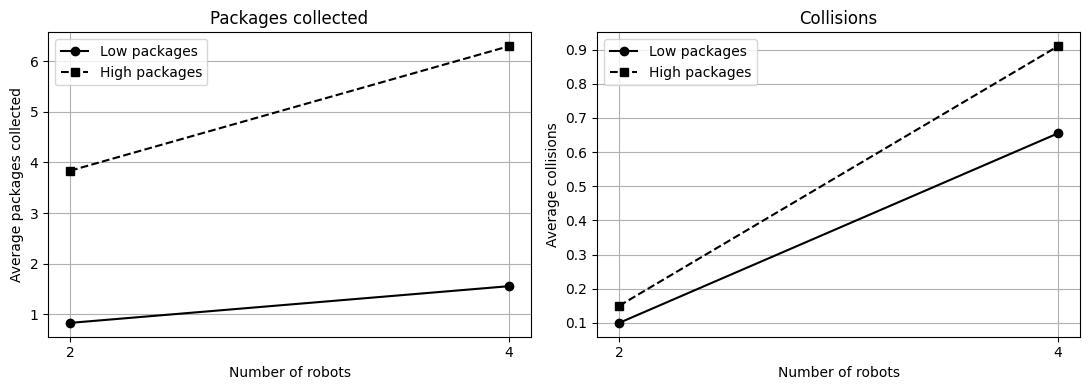

In [5]:
# Plots (black and white)
low = [r for r in results if r[1] == "Low (4 packages)"]
high = [r for r in results if r[1] == "High (12 packages)"]

plt.figure(figsize=(11, 4))

# Plot 1: packages collected
plt.subplot(1, 2, 1)
plt.plot(robot_counts, [r[3] for r in low], "ko-", label="Low packages")
plt.plot(robot_counts, [r[3] for r in high], "ks--", label="High packages")
plt.xticks(robot_counts)
plt.xlabel("Number of robots")
plt.ylabel("Average packages collected")
plt.title("Packages collected")
plt.legend()
plt.grid(True)

# Plot 2: collisions
plt.subplot(1, 2, 2)
plt.plot(robot_counts, [r[4] for r in low], "ko-", label="Low packages")
plt.plot(robot_counts, [r[4] for r in high], "ks--", label="High packages")
plt.xticks(robot_counts)
plt.xlabel("Number of robots")
plt.ylabel("Average collisions")
plt.title("Collisions")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Discussion

**Results (averages of 200 runs)**

| Robots | Packages | Survivors | Packages collected | Collisions | Packages per robot |
|---|---|---|---|---|---|
| 2 | Low (4) | 0.00 | 0.83 | 0.10 | 0.41 |
| 2 | High (12) | 0.00 | 3.83 | 0.15 | 1.92 |
| 4 | Low (4) | 0.00 | 1.55 | 0.66 | 0.39 |
| 4 | High (12) | 0.00 | 6.29 | 0.91 | 1.57 |

**Competition for space and resources.** When the number of robots doubles from 2 to 4, the total packages collected goes up, but by less than double (about 1.9 times at low density and 1.6 times at high density). So each robot collects fewer packages, especially when there are 12 packages, because the robots now share the same packages. Collisions grow much faster than the number of robots (about 6 times more collisions with 4 robots). This is because more robots means many more pairs of robots that can try to enter the same cell. Each collision costs 2 energy, so robots lose energy without getting anything back.

**Efficiency or interference?** Using more robots collects more packages in total, but each robot is less efficient (packages per robot drops from 1.92 to 1.57 at high density) and collisions increase quickly. So in this system interference grows faster than efficiency as robot density increases.

**Main factors affecting performance**
1. Number of robots: more robots gives more collisions and wasted energy.
2. Package density: more packages gives more energy refills, so robots collect many more packages (about 4-5 times more with 12 packages than with 4).
3. Energy limit: robots only start with 5 energy and move randomly, so they run out of energy quickly. This is why survivors is 0 in every case and the 40 steps are never fully used.
4. Randomness: single runs vary a lot, so averages over many runs are used.

**Limitation:** the robots move randomly. A smarter movement rule (for example moving towards the nearest package) would probably give different results.

---
# Part B: Task Allocation Using Genetic Algorithm and Particle Swarm Optimization

## 1. Introduction

Task allocation is an optimization problem in which a set of tasks must be distributed among multiple robots. Each task has a workload, and the objective is to assign tasks to robots so that the maximum total workload assigned to any robot is minimized.

In this notebook, two optimization algorithms are implemented and compared:

* **Genetic Algorithm (GA):** An evolutionary optimization algorithm inspired by natural selection and genetics.
* **Particle Swarm Optimization (PSO):** A population-based optimization algorithm inspired by the collective movement of particles.

Both algorithms solve the same task-allocation problem. Their performance is evaluated using the best makespan obtained, convergence curves, and comparison with the exact optimal solution.

In [6]:
import random
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# Task workloads
tasks = [4, 7, 3, 8, 5, 6]

# Number of robots
num_robots = 3

# Number of tasks
num_tasks = len(tasks)

# Robot names
robot_names = ["Robot A", "Robot B", "Robot C"]

# Calculate total workload
total_workload = sum(tasks)

# Calculate average workload
average_workload = total_workload / num_robots

# Calculate theoretical lower bound
lower_bound = max(max(tasks), int(np.ceil(average_workload)))

print("TASK ALLOCATION PROBLEM")
print("-" * 40)
print("Task workloads:", tasks)
print("Number of tasks:", num_tasks)
print("Number of robots:", num_robots)
print("Total workload:", total_workload)
print("Average workload per robot:", average_workload)
print("Theoretical lower bound:", lower_bound)

TASK ALLOCATION PROBLEM
----------------------------------------
Task workloads: [4, 7, 3, 8, 5, 6]
Number of tasks: 6
Number of robots: 3
Total workload: 33
Average workload per robot: 11.0
Theoretical lower bound: 11


## 2. Problem Description and Objective

The problem consists of six tasks with workloads:

$$
T = [4, 7, 3, 8, 5, 6]
$$

There are three available robots:

* Robot A
* Robot B
* Robot C

Each task must be assigned to exactly one robot.

Let $x_{ij}$ indicate whether task $i$ is assigned to robot $j$. The workload of robot $j$ is:

$$
L_j = \sum_{i=1}^{n} w_i x_{ij}
$$

where $w_i$ represents the workload of task $i$.

The objective is to minimize the **makespan**, defined as the maximum workload assigned to any robot:

$$
\boxed{\text{Makespan} = \max(L_1,L_2,L_3)}
$$

A lower makespan indicates a more balanced allocation of tasks.

The total workload is 33, giving an average workload of 11 per robot. Since the largest individual task has a workload of 8, the theoretical lower bound on the makespan is:

$$
\max\left(8,\left\lceil\frac{33}{3}\right\rceil\right)=11
$$

If a valid allocation achieves a makespan of 11, it is globally optimal because no solution can have a makespan below this lower bound.

Both GA and PSO will attempt to minimize the same objective function.

In [7]:
def calc_makespan(chromosome):
    """
    Calculate the makespan for a task allocation.

    chromosome[i] represents the robot assigned to task i.
    Robot IDs are 0, 1, and 2.
    """

    robot_workloads = [0] * num_robots

    for task_index in range(num_tasks):
        robot_id = chromosome[task_index]
        robot_workloads[robot_id] += tasks[task_index]

    return max(robot_workloads)


def fitness(chromosome):
    """
    Convert makespan into a fitness score.

    A lower makespan produces a higher fitness score.
    """
    return -calc_makespan(chromosome)


# Test the objective function
test_assignment = [0, 1, 2, 0, 1, 2]

print("Test assignment:", test_assignment)
print("Test makespan:", calc_makespan(test_assignment))
print("Test fitness:", fitness(test_assignment))

Test assignment: [0, 1, 2, 0, 1, 2]
Test makespan: 12
Test fitness: -12


## 3. Genetic Algorithm (GA)

The Genetic Algorithm is an evolutionary optimization method that improves a population of candidate solutions over successive generations.

### Solution Representation

Each candidate solution is represented by a chromosome containing six integers. Each integer indicates the robot assigned to the corresponding task:

* 0 represents Robot A.
* 1 represents Robot B.
* 2 represents Robot C.

For example:

$$
[0,1,2,0,1,2]
$$

means that tasks 1 and 4 are assigned to Robot A, tasks 2 and 5 to Robot B, and tasks 3 and 6 to Robot C.

### Genetic Algorithm Operations

1. **Initialization:** Generate a random population of candidate task allocations.
2. **Fitness evaluation:** Evaluate each chromosome using the negative makespan.
3. **Tournament selection:** Select parents by comparing randomly selected candidates.
4. **Crossover:** Combine two parents to create a new candidate solution.
5. **Mutation:** Randomly change the robot assigned to one task.
6. **Elitism:** Preserve the best chromosome from each generation.
7. **Termination:** Repeat the process for a fixed number of generations.

The best makespan from each generation is recorded to evaluate convergence.

In [8]:
# Genetic Algorithm parameters
pop_size = 12
num_generations = 30
mutation_rate = 0.3

# Set random seed for reproducibility
random.seed(2)


# Generate a random chromosome
def create_chromosome():
    return [random.randint(0, num_robots - 1) for _ in range(num_tasks)]


# Generate the initial population
population = [create_chromosome() for _ in range(pop_size)]


# Tournament selection
def tournament_selection(population, k=2):
    candidates = random.sample(population, k)
    winner = max(candidates, key=fitness)
    return winner.copy()


# Single-point crossover
def crossover(parent1, parent2):
    crossover_point = random.randint(1, num_tasks - 1)

    child1 = (
        parent1[:crossover_point]
        + parent2[crossover_point:]
    )

    child2 = (
        parent2[:crossover_point]
        + parent1[crossover_point:]
    )

    return child1, child2


# Mutation
def mutate(chromosome):
    chromosome = chromosome.copy()

    if random.random() < mutation_rate:
        task_index = random.randint(0, num_tasks - 1)

        current_robot = chromosome[task_index]

        possible_robots = [
            robot for robot in range(num_robots)
            if robot != current_robot
        ]

        chromosome[task_index] = random.choice(possible_robots)

    return chromosome


# Track the best makespan in each generation
best_makespan_per_gen = []

# Run the Genetic Algorithm
for generation in range(num_generations):

    # Evaluate the current population
    best_chromosome = max(population, key=fitness)
    best_makespan = calc_makespan(best_chromosome)

    # Record the best result
    best_makespan_per_gen.append(best_makespan)

    # Start the next generation with the elite individual
    new_population = [best_chromosome.copy()]

    # Create the remaining individuals
    while len(new_population) < pop_size:

        parent1 = tournament_selection(population)
        parent2 = tournament_selection(population)

        child1, child2 = crossover(parent1, parent2)

        child1 = mutate(child1)
        child2 = mutate(child2)

        new_population.append(child1)

        if len(new_population) < pop_size:
            new_population.append(child2)

    # Replace the old population
    population = new_population


# Retrieve the best solution from the final population
ga_best_assignment = max(population, key=fitness).copy()
ga_best_makespan = calc_makespan(ga_best_assignment)

# Save convergence results for later comparison
ga_convergence = best_makespan_per_gen.copy()


# Display the results
print("GENETIC ALGORITHM RESULTS")
print("-" * 40)

for task_index in range(num_tasks):
    robot_id = ga_best_assignment[task_index]

    print(
        f"Task {task_index + 1} "
        f"(workload = {tasks[task_index]}) "
        f"-> {robot_names[robot_id]}"
    )

print("\nBest GA makespan:", ga_best_makespan)

GENETIC ALGORITHM RESULTS
----------------------------------------
Task 1 (workload = 4) -> Robot C
Task 2 (workload = 7) -> Robot B
Task 3 (workload = 3) -> Robot A
Task 4 (workload = 8) -> Robot A
Task 5 (workload = 5) -> Robot B
Task 6 (workload = 6) -> Robot C

Best GA makespan: 12


## 4. Genetic Algorithm Convergence

The graph below shows the best makespan found in each generation.

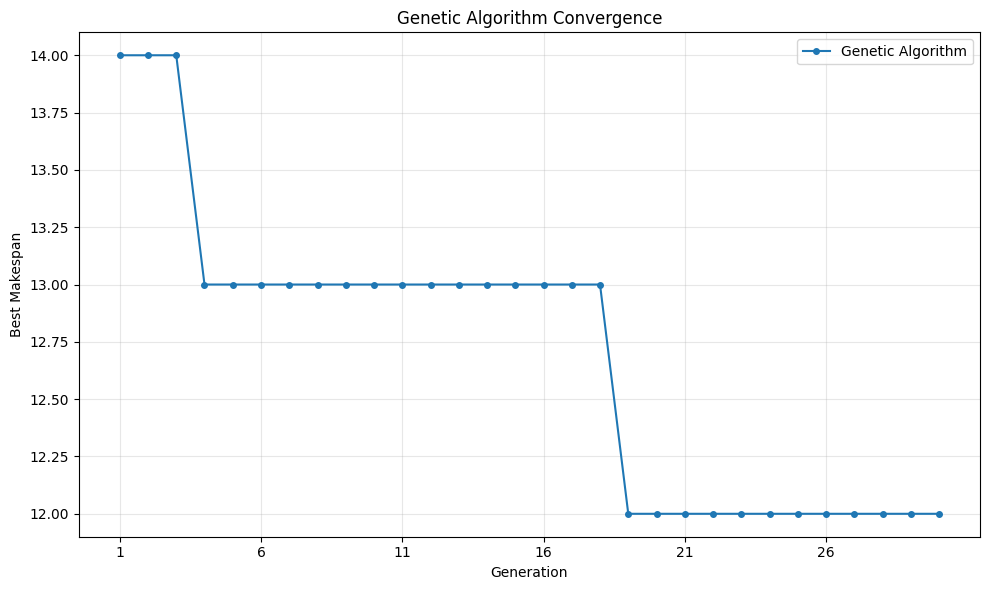

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, num_generations + 1),
    ga_convergence,
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Genetic Algorithm"
)

plt.title("Genetic Algorithm Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Makespan")

plt.xticks(range(1, num_generations + 1, 5))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## 5. Particle Swarm Optimization (PSO)

Particle Swarm Optimization is a population-based optimization algorithm inspired by the collective behaviour of birds and fish.

Each particle represents a possible task allocation. In this implementation, a particle has six continuous position values, one for each task.

The continuous values are converted into robot assignments by rounding them to the nearest integer and restricting them to the range 0–2.

### Particle Movement

Each particle maintains:

* **Position:** Its current candidate solution.
* **Velocity:** The direction and magnitude of its movement.
* **Personal best:** The best solution found by that particle.
* **Global best:** The best solution found by the entire swarm.

The velocity update is:

$$
v_i(t+1)=wv_i(t)+c_1r_1(p_i-x_i(t))+c_2r_2(g-x_i(t))
$$

The position update is:

$$
x_i(t+1)=x_i(t)+v_i(t+1)
$$

where:

* $w$ is the inertia weight.
* $c_1$ is the cognitive coefficient.
* $c_2$ is the social coefficient.
* $r_1$ and $r_2$ are random values between 0 and 1.
* $p_i$ is the particle's personal best position.
* $g$ is the global best position.

After updating positions, each particle is decoded into a valid robot assignment, and its makespan is evaluated.

The best makespan is recorded at initialization and after every iteration.

In [10]:
# PSO parameters
num_particles = 12
num_iterations = 30

w = 0.7
c1 = 1.5
c2 = 1.5

# Set random seed for reproducibility
rng = np.random.default_rng(42)


# Convert continuous particle position into robot assignments
def decode_position(position):
    assignment = np.rint(position).astype(int)

    assignment = np.clip(
        assignment,
        0,
        num_robots - 1
    )

    return assignment.tolist()


# Initialize particle positions
positions = rng.uniform(
    0,
    num_robots - 1,
    size=(num_particles, num_tasks)
)

# Initialize particle velocities
velocities = rng.uniform(
    -1,
    1,
    size=(num_particles, num_tasks)
)


# Initialize personal best positions
personal_best_positions = positions.copy()

personal_best_scores = []

for particle_index in range(num_particles):
    assignment = decode_position(positions[particle_index])

    personal_best_scores.append(
        calc_makespan(assignment)
    )

personal_best_scores = np.array(personal_best_scores)


# Initialize global best
best_particle_index = np.argmin(personal_best_scores)

global_best_position = (
    personal_best_positions[best_particle_index].copy()
)

global_best_makespan = personal_best_scores[best_particle_index]


# Store initial global best makespan
pso_convergence = [global_best_makespan]


# Run PSO
for iteration in range(num_iterations):

    for particle_index in range(num_particles):

        # Generate random coefficients
        r1 = rng.random(num_tasks)
        r2 = rng.random(num_tasks)

        # Update velocity
        velocities[particle_index] = (
            w * velocities[particle_index]
            + c1 * r1 * (
                personal_best_positions[particle_index]
                - positions[particle_index]
            )
            + c2 * r2 * (
                global_best_position
                - positions[particle_index]
            )
        )

        # Update position
        positions[particle_index] = (
            positions[particle_index]
            + velocities[particle_index]
        )

        # Decode the new position
        assignment = decode_position(
            positions[particle_index]
        )

        # Evaluate the current solution
        current_makespan = calc_makespan(assignment)

        # Update personal best
        if current_makespan < personal_best_scores[particle_index]:

            personal_best_scores[particle_index] = current_makespan

            personal_best_positions[particle_index] = (
                positions[particle_index].copy()
            )

        # Update global best
        if current_makespan < global_best_makespan:

            global_best_makespan = current_makespan

            global_best_position = (
                positions[particle_index].copy()
            )

    # Record the best result after this iteration
    pso_convergence.append(global_best_makespan)


# Decode the final global best position
pso_best_assignment = decode_position(global_best_position)

pso_best_makespan = calc_makespan(pso_best_assignment)

pso_workloads = [0] * num_robots

for task_index in range(num_tasks):
    robot_id = pso_best_assignment[task_index]

    pso_workloads[robot_id] += tasks[task_index]


# Display PSO results
print("PARTICLE SWARM OPTIMIZATION RESULTS")
print("-" * 40)

for task_index in range(num_tasks):
    robot_id = pso_best_assignment[task_index]

    print(
        f"Task {task_index + 1} "
        f"(workload = {tasks[task_index]}) "
        f"-> {robot_names[robot_id]}"
    )

print("\nBest PSO makespan:", pso_best_makespan)
print("Robot workloads:", pso_workloads)

PARTICLE SWARM OPTIMIZATION RESULTS
----------------------------------------
Task 1 (workload = 4) -> Robot C
Task 2 (workload = 7) -> Robot C
Task 3 (workload = 3) -> Robot A
Task 4 (workload = 8) -> Robot A
Task 5 (workload = 5) -> Robot B
Task 6 (workload = 6) -> Robot B

Best PSO makespan: 11
Robot workloads: [11, 11, 11]


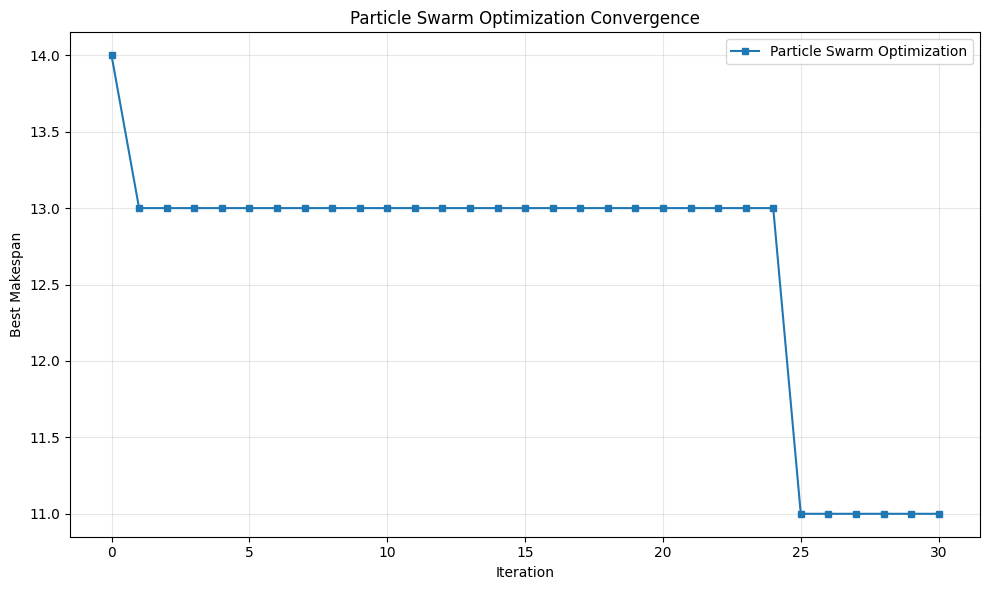

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(pso_convergence)),
    pso_convergence,
    marker="s",
    markersize=4,
    linewidth=1.5,
    label="Particle Swarm Optimization"
)

plt.title("Particle Swarm Optimization Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Makespan")

plt.xticks(range(0, num_iterations + 1, 5))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## 6. Particle Swarm Optimization Results

The PSO algorithm was executed using 12 particles over 30 iterations.

Each particle represents a candidate allocation. Its position and velocity are updated using its personal best position and the global best position found by the swarm.

The convergence graph includes the initial global best makespan at iteration 0, followed by the best makespan after each of the 30 iterations.

A decreasing curve indicates that PSO has discovered a better allocation. A flat curve indicates that no better makespan has been found during that interval.

The final PSO makespan and corresponding allocation are compared against the Genetic Algorithm in the following sections.

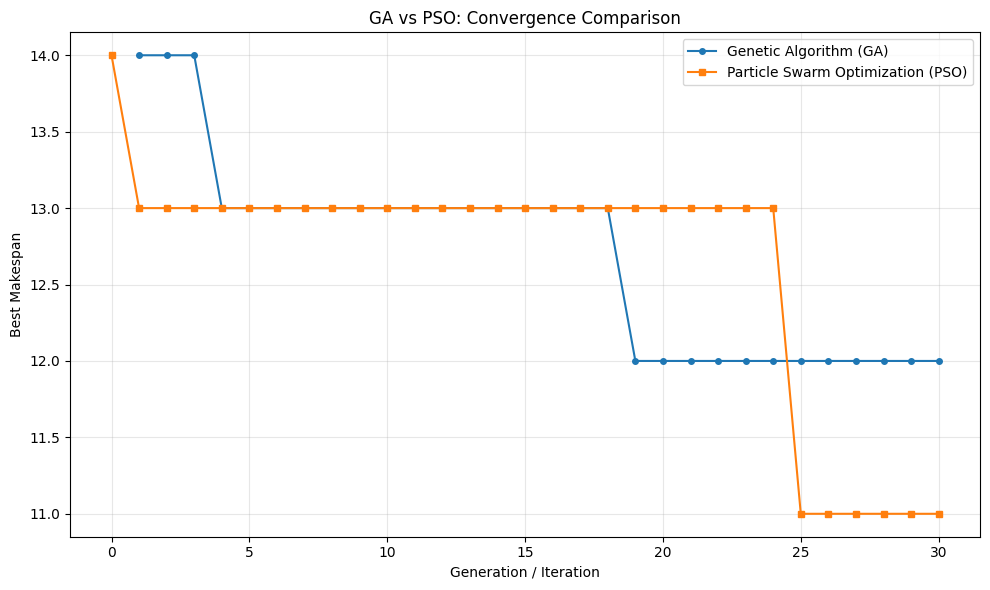

GA VS PSO COMPARISON
GA Best Makespan:  12
PSO Best Makespan: 11
Theoretical Lower Bound: 11

Comparison:
PSO obtained the lower makespan in this experiment.

Distance from the theoretical lower bound:
GA gap:  1
PSO gap: 0


In [12]:
plt.figure(figsize=(10, 6))

# GA convergence
plt.plot(
    range(1, len(ga_convergence) + 1),
    ga_convergence,
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Genetic Algorithm (GA)"
)

# PSO convergence
plt.plot(
    range(len(pso_convergence)),
    pso_convergence,
    marker="s",
    markersize=4,
    linewidth=1.5,
    label="Particle Swarm Optimization (PSO)"
)

plt.title("GA vs PSO: Convergence Comparison")
plt.xlabel("Generation / Iteration")
plt.ylabel("Best Makespan")

plt.xticks(range(0, num_iterations + 1, 5))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

print("GA VS PSO COMPARISON")
print("=" * 40)

print(f"GA Best Makespan:  {ga_best_makespan}")
print(f"PSO Best Makespan: {pso_best_makespan}")
print(f"Theoretical Lower Bound: {lower_bound}")

print("\nComparison:")

if ga_best_makespan < pso_best_makespan:
    print("GA obtained the lower makespan in this experiment.")

elif pso_best_makespan < ga_best_makespan:
    print("PSO obtained the lower makespan in this experiment.")

else:
    print("GA and PSO obtained the same makespan.")

print("\nDistance from the theoretical lower bound:")
print(f"GA gap:  {ga_best_makespan - lower_bound}")
print(f"PSO gap: {pso_best_makespan - lower_bound}")

## 7. Finding the Exact Optimal Solution

Both GA and PSO are optimization algorithms that search for good solutions. Their results depend on the search process and algorithm parameters, so their final solutions are not automatically guaranteed to be optimal.

For this problem, there are only three possible robot assignments for each of the six tasks. Therefore, the total number of possible allocations is:

$$
3^6 = 729
$$

This is small enough to evaluate every possible allocation using exhaustive search.

The exact optimal makespan can then be compared with the results obtained by GA and PSO. If an algorithm achieves the same makespan as the exhaustive-search solution, it has found an optimal solution for this problem.

In [13]:
# Generate every possible task allocation
all_assignments = product(
    range(num_robots),
    repeat=num_tasks
)

exact_best_assignment = None
exact_best_makespan = float("inf")

number_of_allocations = 0

for assignment_tuple in all_assignments:

    assignment = list(assignment_tuple)

    makespan = calc_makespan(assignment)

    number_of_allocations += 1

    if makespan < exact_best_makespan:

        exact_best_makespan = makespan
        exact_best_assignment = assignment.copy()


# Calculate exact optimal robot workloads
exact_robot_workloads = [0] * num_robots

for task_index in range(num_tasks):

    robot_id = exact_best_assignment[task_index]

    exact_robot_workloads[robot_id] += tasks[task_index]


print("EXHAUSTIVE SEARCH RESULTS")
print("=" * 40)

print("Number of allocations evaluated:", number_of_allocations)

for task_index in range(num_tasks):

    robot_id = exact_best_assignment[task_index]

    print(
        f"Task {task_index + 1} "
        f"(workload = {tasks[task_index]}) "
        f"-> {robot_names[robot_id]}"
    )

print("\nExact optimal makespan:", exact_best_makespan)
print("Exact optimal robot workloads:", exact_robot_workloads)

print("\nTheoretical lower bound:", lower_bound)

if exact_best_makespan == lower_bound:
    print("The exact solution achieves the theoretical lower bound.")
else:
    print("The exact solution is above the theoretical lower bound.")

EXHAUSTIVE SEARCH RESULTS
Number of allocations evaluated: 729
Task 1 (workload = 4) -> Robot A
Task 2 (workload = 7) -> Robot A
Task 3 (workload = 3) -> Robot B
Task 4 (workload = 8) -> Robot B
Task 5 (workload = 5) -> Robot C
Task 6 (workload = 6) -> Robot C

Exact optimal makespan: 11
Exact optimal robot workloads: [11, 11, 11]

Theoretical lower bound: 11
The exact solution achieves the theoretical lower bound.


In [14]:
# Create a comparison table
results = {
    "Algorithm": [
        "Genetic Algorithm (GA)",
        "Particle Swarm Optimization (PSO)",
        "Exhaustive Search"
    ],
    "Best Makespan": [
        ga_best_makespan,
        pso_best_makespan,
        exact_best_makespan
    ],
    "Gap from Exact Optimum": [
        ga_best_makespan - exact_best_makespan,
        pso_best_makespan - exact_best_makespan,
        exact_best_makespan - exact_best_makespan
    ],
    "Optimal Solution Found": [
        ga_best_makespan == exact_best_makespan,
        pso_best_makespan == exact_best_makespan,
        True
    ]
}

print(f"{'Algorithm':<35} {'Makespan':<12} {'Gap':<8} {'Optimal?'}")
print("-" * 75)

for i in range(len(results["Algorithm"])):

    print(
        f"{results['Algorithm'][i]:<35} "
        f"{results['Best Makespan'][i]:<12} "
        f"{results['Gap from Exact Optimum'][i]:<8} "
        f"{results['Optimal Solution Found'][i]}"
    )

Algorithm                           Makespan     Gap      Optimal?
---------------------------------------------------------------------------
Genetic Algorithm (GA)              12           1        False
Particle Swarm Optimization (PSO)   11           0        True
Exhaustive Search                   11           0        True


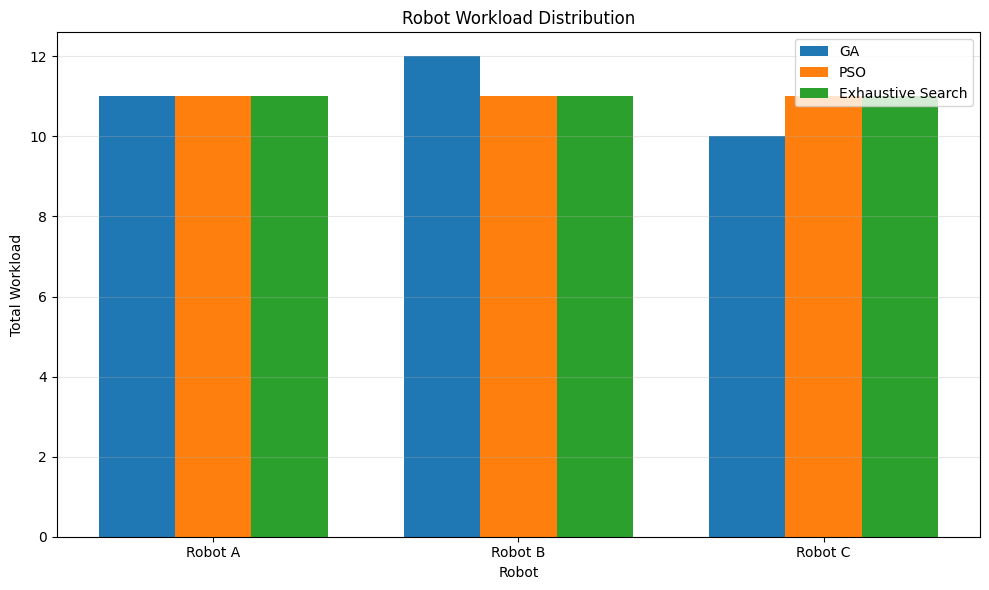

In [15]:
# Calculate workloads for GA
ga_workloads = [0] * num_robots

for task_index in range(num_tasks):

    robot_id = ga_best_assignment[task_index]

    ga_workloads[robot_id] += tasks[task_index]


# Calculate workloads for PSO
pso_workloads = [0] * num_robots

for task_index in range(num_tasks):

    robot_id = pso_best_assignment[task_index]

    pso_workloads[robot_id] += tasks[task_index]


# Calculate workloads for exhaustive search
exact_workloads = [0] * num_robots

for task_index in range(num_tasks):

    robot_id = exact_best_assignment[task_index]

    exact_workloads[robot_id] += tasks[task_index]


# Display workload comparison
x = np.arange(num_robots)
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - width,
    ga_workloads,
    width,
    label="GA"
)

plt.bar(
    x,
    pso_workloads,
    width,
    label="PSO"
)

plt.bar(
    x + width,
    exact_workloads,
    width,
    label="Exhaustive Search"
)

plt.title("Robot Workload Distribution")
plt.xlabel("Robot")
plt.ylabel("Total Workload")

plt.xticks(x, robot_names)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## 8. Discussion and Conclusion

The Genetic Algorithm and Particle Swarm Optimization were applied to the same task-allocation problem. Their performance was evaluated using the best makespan obtained and the convergence curves.

The algorithm with the lower final makespan produced the better allocation in this experiment. The convergence curves also help show how quickly each algorithm discovered improved solutions and whether its progress eventually stabilized.

Exhaustive search was used to calculate the exact optimal makespan because the problem contains only $3^6 = 729$ possible allocations. This provides a reliable reference for evaluating the solutions obtained by GA and PSO.

### Which method is more effective for this problem?

The more effective method is the one that achieves the lower makespan, preferably matching the exact optimum. If both algorithms reach the exact optimum, they are equally effective in terms of solution quality for this particular run. Their convergence behaviour and computational time can then be considered to distinguish their practical performance.

However, a single run is not sufficient to establish that one algorithm is universally better. Both methods are stochastic, and their results can vary with random initialization and parameter settings.

### Final Conclusion

This experiment demonstrates how population-based optimization algorithms can solve task-allocation problems by searching for a balanced distribution of workloads. GA uses selection, crossover, and mutation, whereas PSO updates candidate solutions using personal and global best positions.

The exhaustive-search result provides a benchmark for determining whether either method found the optimal solution. For this small problem, exhaustive search is practical and guarantees the exact answer, while GA and PSO demonstrate approaches that can be applied to larger optimization problems where evaluating every possible allocation may be infeasible.